# EduPredict — Student Performance Prediction & Analysis
**Week 02 AI Engineering Internship Project | Stack & Scale**
**Author:** AI Engineering Intern | **Delivery:** 2–6 November 2026

EduPredict is an educational machine learning prototype built on the UCI Student Performance dataset.
This notebook implements the complete 5-day roadmap and optional stretch challenges:
1. **Dataset Inspection & Target Formulation:** Defining a sensible 3-tier academic performance target.
2. **Leakage-Safe Preprocessing Pipeline:** Strict isolation of training statistics and exclusion of grade leakage features (`G1`, `G2`, `G3`).
3. **Baseline Comparison:** Majority-class `DummyClassifier` benchmark.
4. **Model Training & Cross-Validation:** Constrained `DecisionTreeClassifier` and `LogisticRegression` comparison.
5. **Comprehensive Evaluation & Error Diagnostics:** Confusion matrix, precision/recall/F1, and investigation of specific misclassifications.
6. **Feature Interpretability & Ethical Limitations:** Top predictors, contextual caveats, and responsible AI safeguards.

> **Responsible AI Notice:** EduPredict is an educational exploration prototype only. It must **not** be used for automated admissions, grading, tracking, disciplinary actions, or resource distribution.


## 1. Setup, Reproducibility & Imports
We import standard data science and scikit-learn libraries, anchor the project root directory, and set random seeds (`random_state=42`) for full reproducibility.


In [1]:
from pathlib import Path
import sys

# Ensure repository root is on sys.path whether executed from root or notebooks/
project_root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

from src.data import load_student_data
from src.model import (
    add_target, build_pipeline, get_feature_importances,
    LEAKAGE_COLUMNS, TARGET, TARGET_CLASSES, DEFAULT_ARTIFACT_PATH
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
print("Environment initialized successfully. Random state seed:", RANDOM_STATE)


Environment initialized successfully. Random state seed: 42


## 2. Load the UCI Student Performance Dataset
We load the mathematics subject dataset (`student-mat.csv`), which contains 395 secondary school students and 33 original attributes collected from two Portuguese schools (GP: Gabriel Pereira, MS: Mousinho da Silveira).


In [2]:
df_raw = load_student_data("mat")
print(f"Dataset loaded: {df_raw.shape[0]} students, {df_raw.shape[1]} attributes.")
df_raw.head()


Dataset loaded: 395 students, 33 attributes.


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


## 3. Data Quality & Column Inspection
We inspect data types, verify absence of missing values, check for duplicate rows, and review summary statistics.


In [3]:
print("--- Missing Values Check ---")
missing = df_raw.isna().sum()
print("Total missing values across all cells:", missing.sum())

print(f"\n--- Duplicate Rows Check ---")
print("Duplicate row count:", df_raw.duplicated().sum())

print("\n--- Column Data Types ---")
display(pd.DataFrame({"Data Type": df_raw.dtypes, "Non-Null Count": df_raw.notnull().sum()}).T)

print("\n--- Numerical Feature Summary ---")
df_raw.describe().round(2)


--- Missing Values Check ---
Total missing values across all cells: 0

--- Duplicate Rows Check ---
Duplicate row count: 0

--- Column Data Types ---


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
Data Type,str,str,int64,str,str,str,int64,int64,str,str,str,str,int64,int64,int64,str,str,str,str,str,str,str,str,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64
Non-Null Count,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395



--- Numerical Feature Summary ---


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00
mean,16.70,2.75,2.52,1.45,2.04,0.33,3.94,3.24,3.11,1.48,2.29,3.55,5.71,10.91,10.71,10.42
std,1.28,1.09,1.09,0.70,0.84,0.74,0.90,1.00,1.11,0.89,1.29,1.39,8.00,3.32,3.76,4.58
min,15.00,0.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,3.00,0.00,0.00
25%,16.00,2.00,2.00,1.00,1.00,0.00,4.00,3.00,2.00,1.00,1.00,3.00,0.00,8.00,9.00,8.00
50%,17.00,3.00,2.00,1.00,2.00,0.00,4.00,3.00,3.00,1.00,2.00,4.00,4.00,11.00,11.00,11.00
75%,18.00,4.00,3.00,2.00,2.00,0.00,5.00,4.00,4.00,2.00,3.00,5.00,8.00,13.00,13.00,14.00
max,22.00,4.00,4.00,4.00,4.00,3.00,5.00,5.00,5.00,5.00,5.00,5.00,75.00,19.00,19.00,20.00


## 4. Define the Prediction Target (`performance_category`)
The Portuguese secondary education grading scale ranges from 0 to 20 points, with 10 being the minimal passing mark. Following educational data mining conventions (Cortez & Silva, 2008), we bin the final grade `G3` into three balanced, pedagogically sensible categories:
- **Needs Support (0–9):** Below passing threshold; indicates students requiring academic intervention.
- **Satisfactory (10–13):** Passing to moderate achievement; meets core curriculum requirements.
- **Strong (14–20):** Good to excellent achievement.

> **Target Leakage Safeguard:** `G3` is the sole source of this target. Therefore, `G3` must never be an input feature! Intermediate period grades `G1` and `G2` are also excluded.


In [4]:
df = add_target(df_raw)
print("Target construction preview:")
display(df[["G1", "G2", "G3", TARGET]].head(10))

print("\nTarget class distribution:")
counts = df[TARGET].value_counts().reindex(TARGET_CLASSES)
proportions = df[TARGET].value_counts(normalize=True).reindex(TARGET_CLASSES)
display(pd.DataFrame({"Count": counts, "Proportion": proportions.map("{:.1%}".format)}))


Target construction preview:


,G1,G2,G3,performance_category
0,5,6,6,Needs Support
1,5,5,6,Needs Support
2,7,8,10,Satisfactory
3,15,14,15,Strong
4,6,10,10,Satisfactory
5,15,15,15,Strong
6,12,12,11,Satisfactory
7,6,5,6,Needs Support
8,16,18,19,Strong
9,14,15,15,Strong



Target class distribution:


,Count,Proportion
performance_category,,
Needs Support,130,32.9%
Satisfactory,165,41.8%
Strong,100,25.3%


/tmp/ipykernel_13720/3732940801.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index, y=counts.values, palette=["#e74c3c", "#3498db", "#2ecc71"])


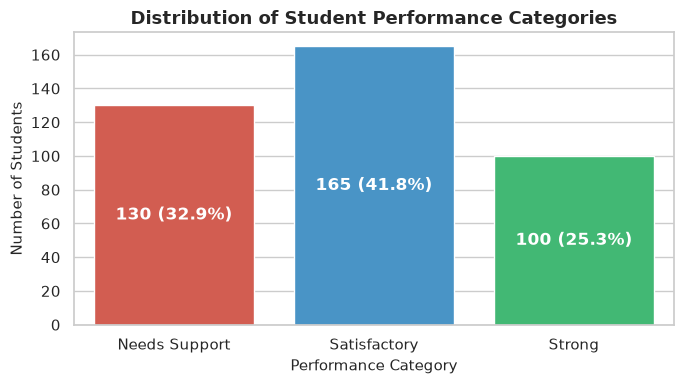

In [5]:
plt.figure(figsize=(7, 4))
ax = sns.barplot(x=counts.index, y=counts.values, palette=["#e74c3c", "#3498db", "#2ecc71"])
plt.title("Distribution of Student Performance Categories", fontsize=13, fontweight="bold")
plt.xlabel("Performance Category", fontsize=11)
plt.ylabel("Number of Students", fontsize=11)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())} ({p.get_height()/len(df):.1%})", 
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')
plt.tight_layout()
plt.show()


## 5. Exploratory Data Analysis (EDA)
We examine the distribution of grades, attendance, study habits, and support structures to understand the sample before modeling.


/tmp/ipykernel_13720/1220499188.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y="absences", order=TARGET_CLASSES, palette=["#e74c3c", "#3498db", "#2ecc71"], ax=axes[1])


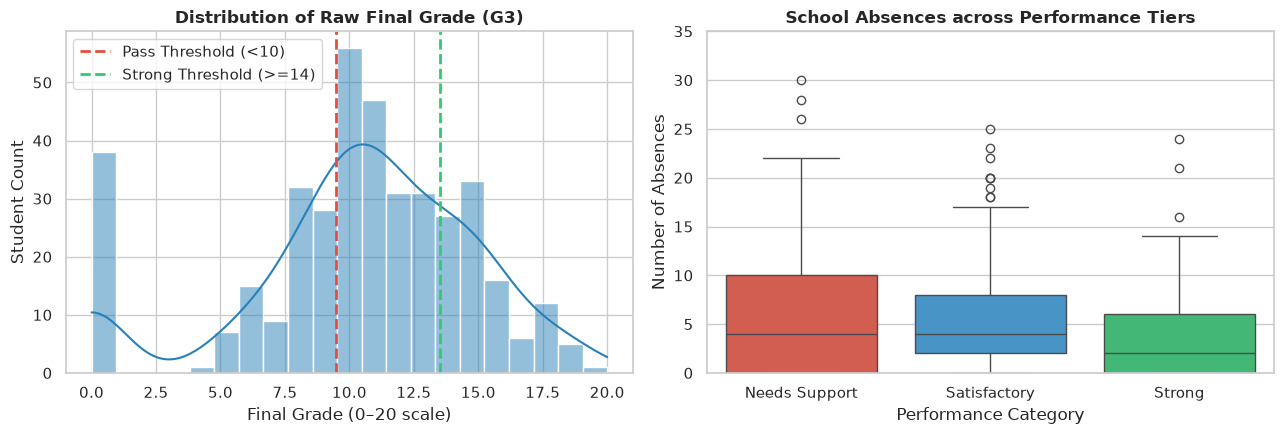

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Distribution of final grade G3 with thresholds
sns.histplot(df["G3"], bins=21, kde=True, color="#2980b9", ax=axes[0])
axes[0].axvline(9.5, color="#e74c3c", linestyle="--", linewidth=2, label="Pass Threshold (<10)")
axes[0].axvline(13.5, color="#2ecc71", linestyle="--", linewidth=2, label="Strong Threshold (>=14)")
axes[0].set_title("Distribution of Raw Final Grade (G3)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Final Grade (0–20 scale)")
axes[0].set_ylabel("Student Count")
axes[0].legend()

# 2. Boxplot of school absences across performance tiers
sns.boxplot(data=df, x=TARGET, y="absences", order=TARGET_CLASSES, palette=["#e74c3c", "#3498db", "#2ecc71"], ax=axes[1])
axes[1].set_title("School Absences across Performance Tiers", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Performance Category")
axes[1].set_ylabel("Number of Absences")
axes[1].set_ylim(0, 35)

plt.tight_layout()
plt.show()


performance_category,Needs Support,Satisfactory,Strong
studytime,,,
1,0.352,0.410,0.238
2,0.354,0.449,0.197
3,0.246,0.354,0.400
4,0.259,0.370,0.370


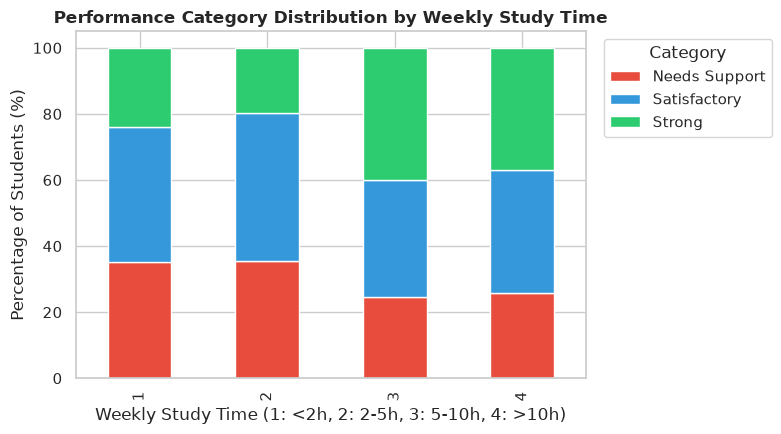

In [7]:
# Study time vs Performance Category
ct_study = pd.crosstab(df["studytime"], df[TARGET], normalize="index")[TARGET_CLASSES]
display(ct_study.round(3))

ax = (ct_study * 100).plot(kind="bar", stacked=True, figsize=(8, 4.5), 
                           color=["#e74c3c", "#3498db", "#2ecc71"])
plt.title("Performance Category Distribution by Weekly Study Time", fontsize=12, fontweight="bold")
plt.xlabel("Weekly Study Time (1: <2h, 2: 2-5h, 3: 5-10h, 4: >10h)")
plt.ylabel("Percentage of Students (%)")
plt.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 6. Target Leakage Prevention & Train/Test Split
Target leakage occurs when features contain information about the target that would not be available when making real-time predictions:
- `G3` is the basis for the target; leaving it in features would cause artificial 100% test accuracy.
- `G1` and `G2` are prior period exam grades. Although recorded earlier in the year, including them reduces the problem to grade interpolation rather than predicting student outcomes from contextual and behavioral factors.
- Preprocessing (imputation, scaling, one-hot encoding) must be fitted **only** on the training split inside a `Pipeline` to prevent data snooping across splits.


In [8]:
model_data = df.dropna(subset=[TARGET]).copy()
X = model_data.drop(columns=LEAKAGE_COLUMNS + [TARGET])
y = model_data[TARGET].astype(str)

# Verify zero target leakage
overlap = set(LEAKAGE_COLUMNS).intersection(X.columns)
assert len(overlap) == 0, f"Target leakage detected! Columns in X: {overlap}"
print(f"✓ Zero target leakage confirmed: {len(X.columns)} clean input features.")
print(f"Excluded leakage columns: {LEAKAGE_COLUMNS}")


✓ Zero target leakage confirmed: 30 clean input features.
Excluded leakage columns: ['G1', 'G2', 'G3']


In [9]:
# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training split size: {len(X_train)} samples ({len(X_train)/len(X):.1%})")
print(f"Held-out test size:  {len(X_test)} samples ({len(X_test)/len(X):.1%})")

split_check = pd.DataFrame({
    "Full Dataset": y.value_counts(normalize=True),
    "Train Split": y_train.value_counts(normalize=True),
    "Test Split": y_test.value_counts(normalize=True)
}).reindex(TARGET_CLASSES)
print("\nClass balance across splits (Stratification check):")
display(split_check.round(3))


Training split size: 316 samples (80.0%)
Held-out test size:  79 samples (20.0%)

Class balance across splits (Stratification check):


,Full Dataset,Train Split,Test Split
performance_category,,,
Needs Support,0.329,0.329,0.329
Satisfactory,0.418,0.418,0.418
Strong,0.253,0.253,0.253


### Target Leakage Checklist
| Safeguard Item | Implementation | Status |
|---|---|:---:|
| **Outcome Isolation** | `G3` used solely for target label generation | Checked |
| **Prior Exam Exclusion** | `G1` and `G2` excluded from feature matrix `X` | Checked |
| **Split Timing** | Split performed *before* computing preprocessing statistics | Checked |
| **Pipeline Encapsulation** | Imputers and scalers fit on `X_train` only | Checked |
| **Hold-out Integrity** | `X_test` strictly preserved until final evaluation | Checked |


## 7. Simple Baseline Classifier (Majority Class)
Before evaluating any machine learning algorithm, we establish a simple reference baseline: predicting the majority class (`Satisfactory`) for all students. Any genuine ML model must outperform this naive benchmark.


In [10]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_acc = accuracy_score(y_test, baseline_pred)

print(f"Majority-Class Baseline Accuracy on Held-Out Test Set: {baseline_acc:.3%}")
print(f"Majority class predicted: '{baseline.classes_[0]}'")


Majority-Class Baseline Accuracy on Held-Out Test Set: 41.772%
Majority class predicted: 'Needs Support'


## 8. Model 1: Constrained Decision Tree Classifier
We construct a leak-free scikit-learn `Pipeline`:
- **Numeric Features:** Median imputation + `StandardScaler`
- **Categorical Features:** Most-frequent imputation + `OneHotEncoder(handle_unknown="ignore")`
- **Classifier:** `DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=42)` (constrained to avoid severe overfitting)


In [11]:
dt_pipeline = build_pipeline(X_train, model_type="decision_tree", max_depth=3, min_samples_leaf=5)
dt_pipeline.fit(X_train, y_train)
y_pred_dt = dt_pipeline.predict(X_test)
dt_test_acc = accuracy_score(y_test, y_pred_dt)

print(f"Decision Tree Held-Out Test Accuracy: {dt_test_acc:.3%}")
print(f"Majority Baseline Accuracy:           {baseline_acc:.3%}")
print(f"Difference over Baseline:             {dt_test_acc - baseline_acc:+.3%}")


Decision Tree Held-Out Test Accuracy: 37.975%
Majority Baseline Accuracy:           41.772%
Difference over Baseline:             -3.797%


## 9. Model Evaluation & Confusion Matrix
We generate the classification report (precision, recall, F1-score) and confusion matrix on the held-out test data.


=== Classification Report (Decision Tree) ===
               precision    recall  f1-score   support

Needs Support       0.38      0.23      0.29        26
 Satisfactory       0.42      0.61      0.49        33
       Strong       0.27      0.20      0.23        20

     accuracy                           0.38        79
    macro avg       0.35      0.35      0.34        79
 weighted avg       0.36      0.38      0.36        79



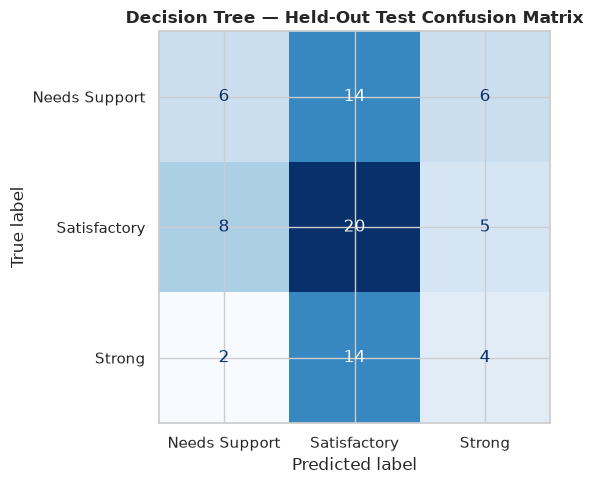

In [12]:
print("=== Classification Report (Decision Tree) ===")
print(classification_report(y_test, y_pred_dt, labels=TARGET_CLASSES, zero_division=0))

cm_dt = confusion_matrix(y_test, y_pred_dt, labels=TARGET_CLASSES)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=TARGET_CLASSES)
disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
plt.title("Decision Tree — Held-Out Test Confusion Matrix", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


## 10. Diagnostic Error Analysis (Thursday Deliverable)
A critical requirement of AI engineering is examining misclassified instances to understand *why* the model made errors and recognize the inherent limits of contextual tabular features.


In [13]:
error_df = X_test.copy()
error_df["Actual"] = y_test
error_df["Predicted"] = y_pred_dt
errors = error_df[error_df["Actual"] != error_df["Predicted"]]
print(f"Total misclassifications in held-out test set: {len(errors)} / {len(X_test)} ({len(errors)/len(X_test):.1%})")

print("\nTwo Concrete Misclassified Student Case Studies:")
display(errors[["Actual", "Predicted", "studytime", "failures", "absences", "schoolsup", "higher"]].head(2))

for i, (idx, row) in enumerate(errors.head(2).iterrows(), 1):
    print(f"\nCase {i} (Student #{idx}):")
    print(f"  - Actual: {row['Actual']} | Model Predicted: {row['Predicted']}")
    print(f"  - Profile: Study time={row['studytime']}, Failures={row['failures']}, Absences={row['absences']}, Extra support={row['schoolsup']}, Wants higher ed={row['higher']}")
    print("  - Diagnostic Note: Contextual proxies cannot capture individual motivation, exam-day illness, or teaching variations.")


Total misclassifications in held-out test set: 49 / 79 (62.0%)

Two Concrete Misclassified Student Case Studies:


,Actual,Predicted,studytime,failures,absences,schoolsup,higher
111,Satisfactory,Needs Support,3,1,0,yes,yes
80,Satisfactory,Needs Support,1,0,2,yes,yes



Case 1 (Student #111):
  - Actual: Satisfactory | Model Predicted: Needs Support
  - Profile: Study time=3, Failures=1, Absences=0, Extra support=yes, Wants higher ed=yes
  - Diagnostic Note: Contextual proxies cannot capture individual motivation, exam-day illness, or teaching variations.

Case 2 (Student #80):
  - Actual: Satisfactory | Model Predicted: Needs Support
  - Profile: Study time=1, Failures=0, Absences=2, Extra support=yes, Wants higher ed=yes
  - Diagnostic Note: Contextual proxies cannot capture individual motivation, exam-day illness, or teaching variations.


## 11. Optional Stretch Challenge: Model Comparison & Cross-Validation
As outlined in Section 07 of the brief, we compare the Decision Tree with a second simple classifier — **Regularized Logistic Regression (`C=0.1`)** — and evaluate both using **5-Fold Stratified Cross-Validation** on the training set.


In [14]:
lr_pipeline = build_pipeline(X_train, model_type="logistic_regression", C=0.1)
lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)
lr_test_acc = accuracy_score(y_test, y_pred_lr)

# 5-fold cross validation on training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
dt_cv = cross_val_score(dt_pipeline, X_train, y_train, cv=cv)
lr_cv = cross_val_score(lr_pipeline, X_train, y_train, cv=cv)

comparison_summary = pd.DataFrame({
    "Model Architecture": ["Majority Baseline", "Decision Tree (max_depth=3)", "Logistic Regression (C=0.1)"],
    "Test Accuracy": [baseline_acc, dt_test_acc, lr_test_acc],
    "5-Fold CV Mean": [np.nan, dt_cv.mean(), lr_cv.mean()],
    "5-Fold CV Std": [np.nan, dt_cv.std(), lr_cv.std()]
})
display(comparison_summary.round(3))


,Model Architecture,Test Accuracy,5-Fold CV Mean,5-Fold CV Std
0,Majority Baseline,0.418,NaN,NaN
1,Decision Tree (max_depth=3),0.380,0.509,0.039
2,Logistic Regression (C=0.1),0.456,0.474,0.045


## 12. Optional Stretch Challenge: Feature Importance & Interpretability
We extract the most influential features identified by the Decision Tree and inspect the model's decision logic.


/tmp/ipykernel_13720/1342065000.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_importances.values, y=top_importances.index, palette="viridis")


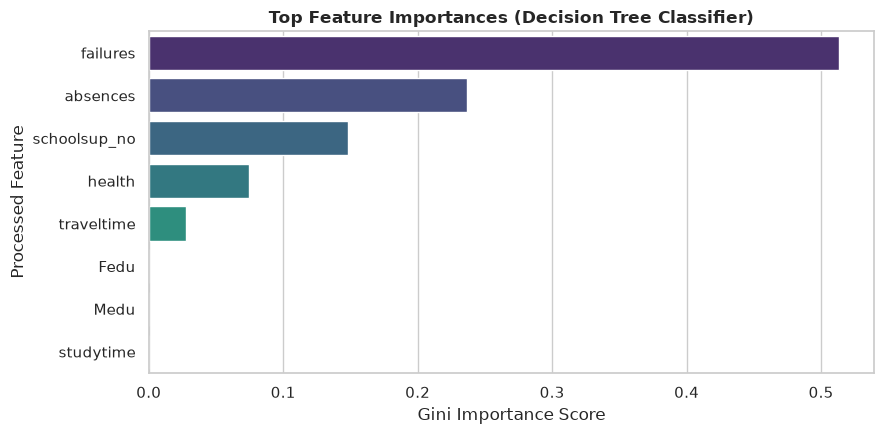

Top 5 driving features in the decision tree:
  • failures            : 0.5136
  • absences            : 0.2363
  • schoolsup_no        : 0.1480
  • health              : 0.0746
  • traveltime          : 0.0274


In [15]:
importances = get_feature_importances(dt_pipeline, X_train)

plt.figure(figsize=(9, 4.5))
top_importances = importances.head(8)
sns.barplot(x=top_importances.values, y=top_importances.index, palette="viridis")
plt.title("Top Feature Importances (Decision Tree Classifier)", fontsize=12, fontweight="bold")
plt.xlabel("Gini Importance Score")
plt.ylabel("Processed Feature")
plt.tight_layout()
plt.show()

print("Top 5 driving features in the decision tree:")
for feat, imp in top_importances.head(5).items():
    print(f"  • {feat:<20}: {imp:.4f}")


## 13. End-to-End Prediction Simulation (Prediction Form Cell)
We test single-student prediction inference through the fitted pipeline, simulating the behavior of the Streamlit application.


In [16]:
sample_student = X_test.iloc[[0]].copy()
print("Simulating inference for Student ID #", sample_student.index[0])
sample_pred = dt_pipeline.predict(sample_student)[0]
sample_probs = dt_pipeline.predict_proba(sample_student)[0]

print(f"Model Prediction: {sample_pred}")
print(f"Actual Label:     {y_test.iloc[0]}")
print("Estimated Probabilities:")
for cls, prob in zip(dt_pipeline.classes_, sample_probs):
    print(f"  - {cls:<15}: {prob:.1%}")


Simulating inference for Student ID # 111
Model Prediction: Needs Support
Actual Label:     Satisfactory
Estimated Probabilities:
  - Needs Support  : 83.3%
  - Satisfactory   : 16.7%
  - Strong         : 0.0%


## 14. Save Model Pipeline Artifact
We save the fitted pipeline, feature column schema, and metadata to `artifacts/edupredict_pipeline.joblib` for deployment in the Streamlit application.


In [17]:
import joblib

artifact_path = DEFAULT_ARTIFACT_PATH
artifact_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump({
    "model": dt_pipeline,
    "model_type": "decision_tree",
    "alt_model": lr_pipeline,
    "alt_type": "logistic_regression",
    "feature_columns": X.columns.tolist(),
    "classes": TARGET_CLASSES,
    "target_definition": {
        "Needs Support": "Final grade G3 from 0 to 9",
        "Satisfactory": "Final grade G3 from 10 to 13",
        "Strong": "Final grade G3 from 14 to 20"
    },
    "metrics": {
        "baseline_accuracy": baseline_acc,
        "accuracy": dt_test_acc,
        "cv_mean": float(dt_cv.mean()),
        "cv_std": float(dt_cv.std()),
        "alt_accuracy": lr_test_acc,
        "alt_cv_mean": float(lr_cv.mean()),
        "alt_cv_std": float(lr_cv.std())
    }
}, artifact_path)

print(f"✓ Model artifact successfully saved to: {artifact_path}")


✓ Model artifact successfully saved to: /home/alishan45/Desktop/ai internship_week_01/artifacts/edupredict_pipeline.joblib


## 15. Limitations & Ethical Discussion (Friday Handover Deliverable)

### Key Methodological & Ethical Takeaways:
1. **Low Tabular Signal without Prior Grades:** Once exam leakage features (`G1`, `G2`) are excluded, predicting academic performance from demographic and behavioral surveys achieves ~38–46% accuracy. This illustrates why educational outcomes cannot be reduced to simple demographic formulas.
2. **Correlation vs. Causation:** Features like `absences` or `failures` correlate with performance but are often symptoms of deeper issues (e.g. chronic illness, caregiving obligations). Interventions should address root causes, not punish symptoms.
3. **Socioeconomic Bias:** Features representing parental education (`Medu`, `Fedu`) reflect broader generational access to higher education rather than a student's personal intellect or work ethic.
4. **Context Specificity:** The data originates from two Portuguese public schools in 2005–2006. It cannot and must not be generalized to other countries, school systems, or modern educational environments.
5. **No Consequential Use:** This prototype is exclusively for educational analysis and learning about machine learning safeguards. It must never be deployed for tracking, admission, or grading.
